# Week 8 demos

In [1]:
import gdown
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import cmocean as cmo
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from scipy.stats import linregress

## Cartopy

### Downloading, loading, and selecting data

In [2]:
# Download from Google Drive
#gdown.download(id="17E0ZXeQBLCFZYyzRYDksrylxy7XpDjBy", output="data/carbon_data.nc")

In [3]:
# Load into python
data = xr.open_dataset('data/carbon_data.nc')
display(data)

<xarray.Dataset> Size: 196MB
Dimensions:    (time: 1, depth: 50, latitude: 681, longitude: 1440)
Coordinates:
  * time       (time) datetime64[ns] 8B 2025-06-01
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 3kB -80.0 -79.75 -79.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Data variables:
    dissic     (time, depth, latitude, longitude) float32 196MB ...
Attributes:
    Conventions:       CF-1.11
    title:             Monthly mean fields for product GLOBAL_ANALYSIS_FORECA...
    institution:       Mercator Ocean
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    source:            MERCATOR BIOMER4V2R1
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_ANALYSISFORECAST_BGC_001_028
    subset:datasetId:  cmems_mod_glo_bgc-car_anfc_0.25deg_P1M-m_202311
    subset:date:       2025-08-04T19:10:23.855Z

In [4]:
# extract the dissolved inorganic carbon data variable
carbon = data['dissic']
display(carbon)

<xarray.DataArray 'dissic' (time: 1, depth: 50, latitude: 681, longitude: 1440)> Size: 196MB
[49032000 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 8B 2025-06-01
  * depth      (depth) float32 200B 0.494 1.541 2.646 ... 5.275e+03 5.728e+03
  * latitude   (latitude) float32 3kB -80.0 -79.75 -79.5 ... 89.5 89.75 90.0
  * longitude  (longitude) float32 6kB -180.0 -179.8 -179.5 ... 179.5 179.8
Attributes:
    units:          mol m-3
    standard_name:  mole_concentration_of_dissolved_inorganic_carbon_in_sea_w...
    long_name:      Dissolved Inorganic Carbon
    unit_long:      moles of DIC per cubic meter
    valid_max:      6.0
    valid_min:      0.0

<!-- BEGIN QUESTION -->

### Your turn #1

From `carbon`, extract the DIC at the sea level and remove the time axis. Call the resulting xarray DataArray `surf_carbon_xr`. Then, obtain the 1D numpy arrays for latitude (`lat`), longitude (`lon`), and the 2D numpy array of surface dissolved inorganic carbon (`surf_carbon`) from `surf_carbon_xr`

In [5]:
# Your code here

surf_carbon_xr = carbon.isel(depth=0).squeeze()
surf_carbon_xr = carbon.sel(depth=0, method="nearest").squeeze()

surf_carbon = surf_carbon_xr.values
lat = surf_carbon_xr.coords["latitude"].values
lon = surf_carbon_xr.coords["longitude"].values

<!-- END QUESTION -->

### Cartopy plots

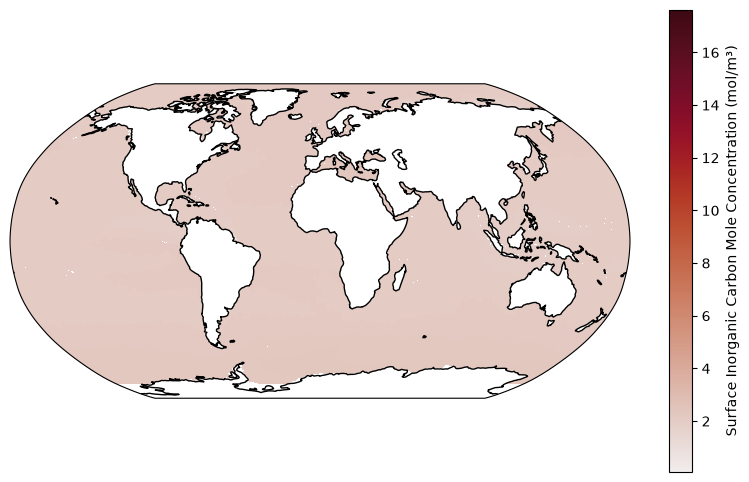

In [6]:
# First attempt

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection=ccrs.Robinson())

mesh = ax.pcolormesh(
    lon, lat, surf_carbon,
    transform=ccrs.PlateCarree(), cmap = cmo.cm.amp
)

cb = fig.colorbar(mesh)
cb.set_label('Surface Inorganic Carbon Mole Concentration (mol/m³)')

ax.coastlines()

plt.show(fig)

<!-- BEGIN QUESTION -->

### Poll #1 (think-pair-share; JupyterHub **off**)

Are there issue(s) in the above plot? How might we fix the problem(s)?

<!-- END QUESTION -->



2.111292 0.10017156


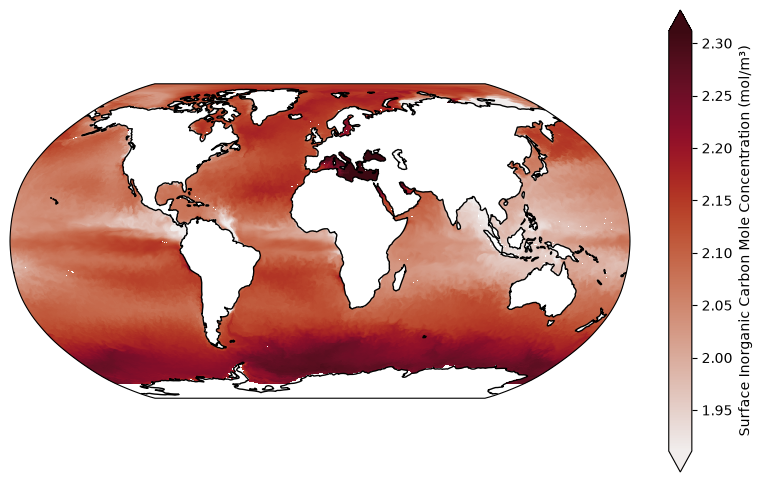

In [7]:
# Let's try to fix the problem we identified

cmean = surf_carbon_xr.mean().values
cstd = surf_carbon_xr.std().values

print(cmean, cstd)

clow = cmean - 2 * cstd
chigh = cmean + 2 * cstd

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection=ccrs.Robinson())

mesh = ax.pcolormesh(
    lon, lat, surf_carbon, vmin = clow, vmax = chigh,
    transform=ccrs.PlateCarree(), cmap = cmo.cm.amp
)

cb = fig.colorbar(mesh, extend="both")
cb.set_label('Surface Inorganic Carbon Mole Concentration (mol/m³)')

ax.coastlines()

plt.show(fig)

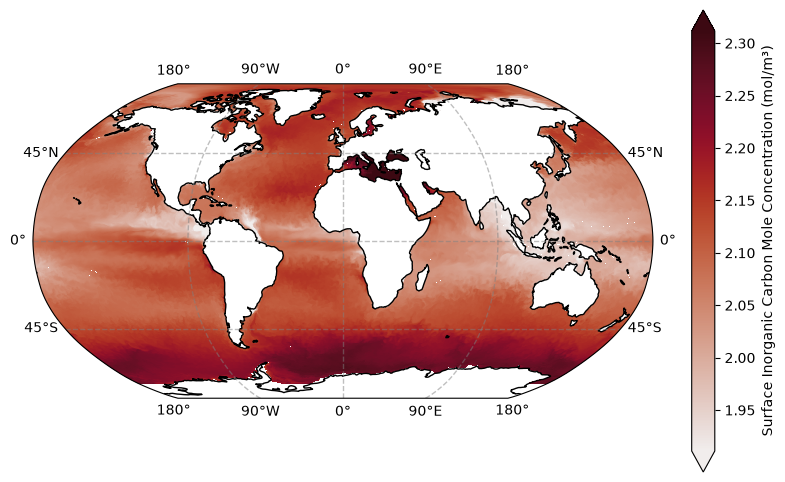

In [8]:
# Adding gridlines

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection=ccrs.Robinson())

mesh = ax.pcolormesh(
    lon, lat, surf_carbon, vmin = clow, vmax = chigh,
    transform=ccrs.PlateCarree(), cmap = cmo.cm.amp
)

cb = fig.colorbar(mesh, extend="both")
cb.set_label('Surface Inorganic Carbon Mole Concentration (mol/m³)')

ax.coastlines()

#### COPY PREVIOUS CODES

gl = ax.gridlines(
    crs=ccrs.PlateCarree(), draw_labels=True,
    linewidth=1, color='gray', alpha=0.5, linestyle='--'
)
gl.xlocator = mticker.FixedLocator(np.arange(-180, 181, 90))
gl.ylocator = mticker.FixedLocator(np.arange(-90, 91, 45))

#### COPY PREVIOUS CODES

plt.show(fig)

### Limiting the plot extent

It appears that the Mediterranean sea is especially carbon rich. Let's "zoom in" and check it out:

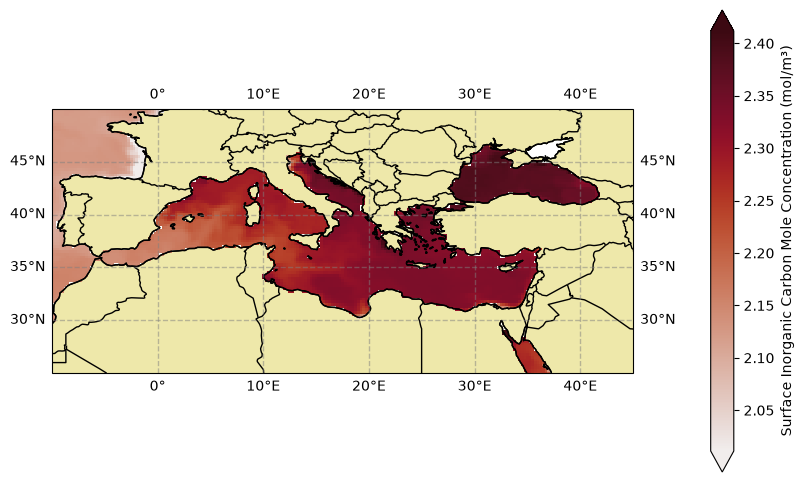

In [9]:
clow2 = cmean - 1 * cstd
chigh2 = cmean + 3 * cstd

fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection=ccrs.PlateCarree())

mesh = ax.pcolormesh(
    lon, lat, surf_carbon, vmin = clow2, vmax = chigh2,
    transform=ccrs.PlateCarree(), cmap = cmo.cm.amp
)

cb = fig.colorbar(mesh, extend="both", pad=0.1)
cb.set_label('Surface Inorganic Carbon Mole Concentration (mol/m³)')

ax.coastlines()

#### COPY/ADJUST PREVIOUS CODES

# Isolates Mediterranean Region
# The format is [lon_min, lon_max, lat_min, lat_max]
ax.set_extent([-10, 45, 25, 50], crs = ccrs.PlateCarree())

ax.add_feature(cfeature.LAND, color="palegoldenrod")
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.COASTLINE)

#### COPY/ADJUST PREVIOUS CODES

gl = ax.gridlines(
    crs=ccrs.PlateCarree(), draw_labels=True,
    linewidth=1, color='gray', alpha=0.5, linestyle='--'
)

plt.show(fig)

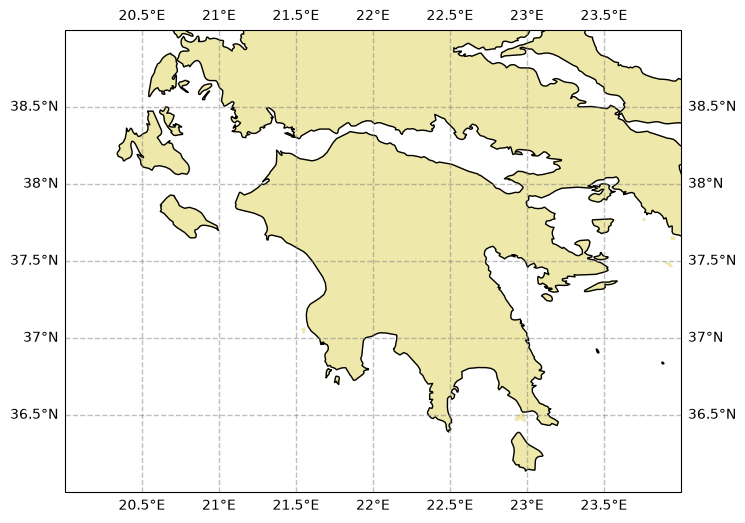

In [10]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection=ccrs.PlateCarree())

#### COPY/ADJUST PREVIOUS CODES

# Isolates Greece
ax.set_extent([20, 24, 36, 39], crs = ccrs.PlateCarree())

# bump zorder to make land above mesh data
ax.add_feature(cfeature.LAND, color="palegoldenrod", zorder=1.5)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.COASTLINE)

#### COPY/ADJUST PREVIOUS CODES

gl = ax.gridlines(
    crs=ccrs.PlateCarree(), draw_labels=True,
    linewidth=1, color='gray', alpha=0.5, linestyle='--'
)

plt.show(fig)

## Linear regression

### Example 1: fish length versus fish weight

As a simple example, consider fish length (in mm) and weight (in g) data taken from Alaskan shore between 1997-2006 (this is the same dataset used in the week 9 preclass reading)

In [11]:
file_url = 'https://raw.githubusercontent.com/OCEAN-215-2026/week_08_demos/refs/heads/main/data/secm_fish_size.csv'
#urlretrieve(file_url, "data/secm_fish_size.csv")

In [12]:
# loading the data
fish = pd.read_csv("data/secm_fish_size.csv")

In [13]:
# subset to include only pollocks
pollock = fish.loc[fish["name_common"]=="Walleye_pollock"]
pollock

,date,haul_id,fish_id,species,name_common,length,weight
10,1997-5-21,1006,1,Theragra_chalcogramma,Walleye_pollock,550.0,980.0
11,1997-5-21,1006,2,Theragra_chalcogramma,Walleye_pollock,522.0,890.0
12,1997-5-21,1006,3,Theragra_chalcogramma,Walleye_pollock,537.0,1050.0
15,1997-5-21,1007,4,Theragra_chalcogramma,Walleye_pollock,489.0,900.0
16,1997-5-21,1007,5,Theragra_chalcogramma,Walleye_pollock,516.0,840.0
...,...,...,...,...,...,...,...
1600,2006-6-22,10016,180,Theragra_chalcogramma,Walleye_pollock,485.0,990.0
1601,2006-6-22,10016,181,Theragra_chalcogramma,Walleye_pollock,502.0,820.0
1602,2006-6-22,10016,182,Theragra_chalcogramma,Walleye_pollock,482.0,825.0
1603,2006-6-22,10016,183,Theragra_chalcogramma,Walleye_pollock,525.0,1050.0


In [14]:
# perform linear regression

lengths = pollock["length"].values
weights = pollock["weight"].values

wt_vs_len = linregress(lengths, weights)

In [15]:
# Check the slope, r, and R^2
print("intercept =", wt_vs_len.intercept)
print("slope =", wt_vs_len.slope)
print("r =", wt_vs_len.rvalue)
print("R^2 =", wt_vs_len.rvalue ** 2)

intercept = -695.4768383961372
slope = 2.9793292254290153
r = 0.9301660567537924
R^2 = 0.8652088931368993


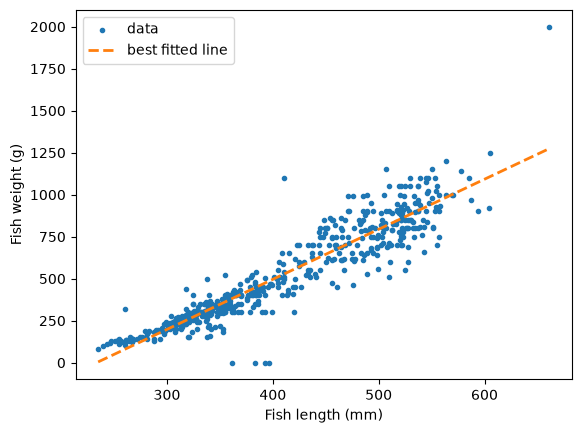

In [16]:
# Plot the data together with the best fitted line

new_lengths = np.array([np.min(lengths), np.max(lengths)])
new_weights = new_lengths * wt_vs_len.slope + wt_vs_len.intercept

fig = plt.figure()
ax = fig.add_subplot()

ax.scatter(lengths, weights, c="tab:blue", marker=".", label="data")
ax.plot(new_lengths, new_weights, ls="--", lw=2, c="tab:orange", label="best fitted line")

ax.set_xlabel("Fish length (mm)")
ax.set_ylabel("Fish weight (g)")

ax.legend()

plt.show(fig)

<!-- BEGIN QUESTION -->

### Poll #2 (JupyterHub **on**)

What would the linear regression model predicts (approximately) as the weight of a pollock, if its length is 500 mm?

+ 700 g
+ 750 g
+ 800 g
+ 850 g

In [17]:
# Your code here
length_given = 500
weight_pred = length_given * wt_vs_len.slope + wt_vs_len.intercept
print(weight_pred)

794.1877743183705


<!-- END QUESTION -->

### Example 2: ice concentration

In [18]:
file_url = 'https://raw.githubusercontent.com/OCEAN-215-2026/week_08_demos/refs/heads/main/data/icec.mnmean.nc'
#urlretrieve(file_url, "data/icec.mnmean.nc")

In [19]:
data = xr.open_dataset('data/icec.mnmean.nc')
ice = data["icec"]
display(ice)

<xarray.DataArray 'icec' (time: 494, lat: 180, lon: 360)> Size: 128MB
[32011200 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-12-01 1982-01-01 ... 2023-01-01
  * lat      (lat) float32 720B 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float32 1kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
Attributes:
    long_name:             Monthly Means of Ice Concentration
    unpacked_valid_range:  [  0. 100.]
    actual_range:          [  0. 122.]
    units:                 %
    precision:             2
    var_desc:              Ice Concentration
    dataset:               NOAA Optimum Interpolation (OI) SST V2
    level_desc:            Surface
    statistic:             Mean
    parent_stat:           Weekly Mean
    cell_methods:          time: mean (monthly from weekly values interpolate...
    valid_range:           [-32765 -22765]

<!-- BEGIN QUESTION -->

### Poll #3 (think-pair-share; Jupyter **Off**)

Which of the following codes can be used to reduce the dimension of the sea ice concentration data by making an average over sea ice concentration in the part of the globe where latitude is above 45°N?

1. ```python
   ice.mean('lat').mean('lon')
   ```
   
2. ```python
   ice.sel(lat = ice.lat > 45).mean('lat')
   ```

3. ```python
   ice.sel(lat = ice.lat > 45).mean('lon')
   ```

4. ```python
   ice.sel(lat = ice.lat > 45).mean(['lat', 'lon'])
   ```

In [20]:
ice_mean = ice.sel(lat = ice.lat > 45).mean(['lat', 'lon'])
display(ice_mean)

<xarray.DataArray 'icec' (time: 494)> Size: 2kB
array([61.240326, 64.90976 , 66.17007 , 66.37532 , 65.59003 , 62.53763 ,
       58.50266 , 51.152317, 45.524765, 43.847683, 51.00223 , 57.443985,
       61.406464, 63.74341 , 65.397644, 65.27296 , 64.045815, 61.505848,
       57.421555, 50.4696  , 44.80846 , 43.188774, 50.44579 , 57.459717,
       61.242664, 63.34832 , 63.85927 , 64.774765, 64.16741 , 61.468643,
       57.34375 , 48.697918, 43.06845 , 41.353848, 47.89817 , 54.95791 ,
       59.521683, 62.36905 , 64.41465 , 64.71248 , 65.10491 , 62.49628 ,
       56.71694 , 47.413372, 42.237457, 41.362885, 48.25234 , 55.799534,
       60.229485, 63.906357, 65.103745, 65.48353 , 64.3108  , 61.756165,
       57.82334 , 50.223534, 45.210354, 44.48735 , 51.245747, 56.805805,
       60.781994, 63.464073, 66.14892 , 65.752235, 64.98767 , 62.02349 ,
       58.521683, 50.75893 , 44.71216 , 44.52955 , 51.204933, 57.499786,
       61.797726, 64.54135 , 65.439095, 66.18984 , 65.17634 , 60.821533,
       56.355335, 48.735756, 44.171345, 43.639244, 51.010735, 58.160606,
       62.999256, 65.291245, 65.384995, 64.944725, 63.114582, 60.764774,
       57.31335 , 50.031464, 45.12415 , 42.493942, 49.391262, 56.30527 ,
       61.476402, 63.36416 , 64.059204, 64.92528 , 62.18346 , 58.886585,
       54.89041 , 46.81994 , 41.81388 , 39.83833 , 47.796238, 56.923576,
       60.96333 , 62.80219 , 64.07961 , 64.74181 , 63.558247, 60.9324  ,
       56.158165, 47.860863, 42.915283, 40.0203  , 48.47364 , 56.076637,
...
       54.23639 , 45.11814 , 37.794205, 34.174896, 43.347652, 52.853657,
       58.590504, 61.289032, 62.372826, 63.12683 , 62.933   , 59.753315,
       53.77925 , 45.699776, 39.157875, 34.84006 , 43.38432 , 54.266335,
       59.378918, 62.251106, 64.03213 , 63.798702, 62.32498 , 59.12909 ,
       53.149426, 44.657825, 35.968563, 33.749386, 42.14579 , 52.231655,
       57.666275, 60.338737, 61.321644, 61.98772 , 61.399254, 57.53365 ,
       51.73062 , 43.338837, 34.396603, 31.725021, 39.05364 , 46.32734 ,
       53.757343, 58.03478 , 60.528637, 61.758816, 61.412125, 58.548874,
       51.930447, 42.22409 , 34.62452 , 32.85824 , 40.466156, 49.74005 ,
       55.753315, 59.424107, 60.278614, 61.753216, 61.434128, 57.53895 ,
       52.375874, 44.90009 , 36.81668 , 34.243343, 38.60566 , 51.82641 ,
       57.544945, 61.739265, 63.325375, 63.893017, 62.08321 , 58.613323,
       52.889084, 43.407406, 34.91787 , 33.36831 , 38.870224, 51.65016 ,
       58.556637, 62.170155, 63.882404, 64.51046 , 62.82729 , 58.990078,
       52.5085  , 41.842224, 33.4862  , 30.052755, 36.303566, 49.212986,
       57.258278, 61.092445, 63.745556, 64.18538 , 62.457314, 59.63366 ,
       53.2179  , 43.770214, 36.670696, 34.94479 , 42.04873 , 53.096275,
       59.040474, 62.368797, 63.64358 , 63.547108, 63.128403, 60.153355,
       53.188133, 44.55575 , 37.722076, 34.875526, 41.722862, 52.677277,
       32.157875, 60.951763], dtype=float32)
Coordinates:
  * time     (time) datetime64[ns] 4kB 1981-12-01 1982-01-01 ... 2023-01-01
Attributes:
    long_name:             Monthly Means of Ice Concentration
    unpacked_valid_range:  [  0. 100.]
    actual_range:          [  0. 122.]
    units:                 %
    precision:             2
    var_desc:              Ice Concentration
    dataset:               NOAA Optimum Interpolation (OI) SST V2
    level_desc:            Surface
    statistic:             Mean
    parent_stat:           Weekly Mean
    cell_methods:          time: mean (monthly from weekly values interpolate...
    valid_range:           [-32765 -22765]

<!-- END QUESTION -->



In [21]:
# convert the time series from xarray to pandas
ice_df = ice_mean.to_dataframe().reset_index()
display(ice_df)

,time,icec
0,1981-12-01,61.240326
1,1982-01-01,64.909760
2,1982-02-01,66.170067
3,1982-03-01,66.375320
4,1982-04-01,65.590027
...,...,...
489,2022-09-01,34.875526
490,2022-10-01,41.722862
491,2022-11-01,52.677277
492,2022-12-01,32.157875


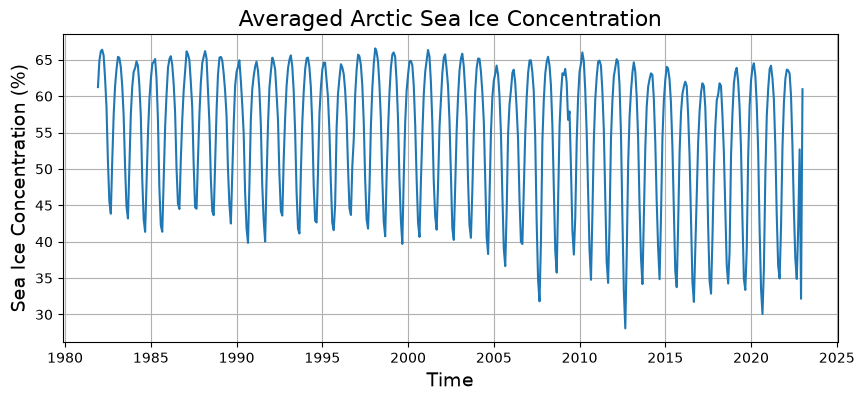

In [22]:
# plot the time series

fig = plt.figure(figsize = (10, 4))
ax = fig.add_subplot()

ax.plot(ice_df.time, ice_df.icec)

ax.set_xlabel('Time', fontsize=14)
ax.set_ylabel('Sea Ice Concentration (%)', fontsize=14)
ax.set_title('Averaged Arctic Sea Ice Concentration', fontsize=16)
ax.grid()

plt.show(fig)

In [23]:
# convert the timestamp to floating point numbers
ice_time_diff = (ice_df.time.values - ice_df.time.values[0])
ice_time_day = ice_time_diff / np.timedelta64(1, 'D')

#display(ice_time_day)

# perform linear regression
ice_trend = linregress(ice_time_day, ice_df.icec.values)

#print(ice_trend)

# print out results
print("intercept =", ice_trend.intercept)
print("slope =", ice_trend.slope, "per day")
print("r =", ice_trend.rvalue)
print("R^2 =", ice_trend.rvalue ** 2)

intercept = 58.206694934469034
slope = -0.0004591394151582536 per day
r = -0.20942982097271626
R^2 = 0.04386084991266398


In [24]:
print("slope =", ice_trend.slope * 365.2425, "per year")

slope = -0.16769722784093843 per year


<!-- BEGIN QUESTION -->

### Your turn #2

Add the regression line to the previous plot. Make sure you follow best practices for good plot

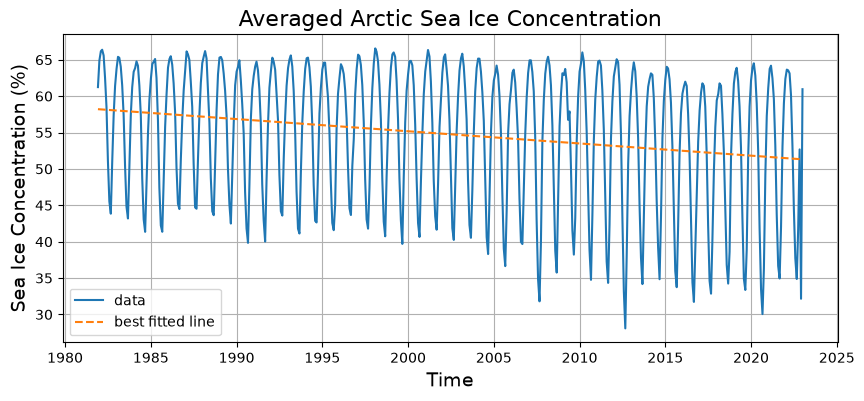

In [25]:
# Generate the array of time and concentration for the best-fitted line

icec_pred = ice_time_day * ice_trend.slope + ice_trend.intercept

# Add the best-fitted line to plot

fig = plt.figure(figsize = (10, 4))
ax = fig.add_subplot()

ax.plot(ice_df.time, ice_df.icec, label="data")
ax.plot(ice_df.time, icec_pred, linestyle="--", label="best fitted line")

ax.set_xlabel('Time', fontsize=14)
ax.set_ylabel('Sea Ice Concentration (%)', fontsize=14)
ax.set_title('Averaged Arctic Sea Ice Concentration', fontsize=16)
ax.grid()

ax.legend()

plt.show(fig)


<!-- END QUESTION -->

